# Phân loại rượu vang bằng KNN, Gaussian Naive Bayes và Random Forest

Ba mô hình được huấn luyện trên 142 mẫu train với 13 đặc trưng. Tập test 36 mẫu được giữ riêng. Phân tích sử dụng F1-macro để đánh giá đồng đều ba lớp và xếp hạng mô hình.

Tên và thứ tự đặc trưng được đọc từ dữ liệu. Bảng dữ liệu đầy đủ dùng để kiểm tra đặc trưng và nhãn khớp nhau theo từng dòng. Mở notebook trong thư mục dự án hoặc đặt đường dẫn dự án trong `PROJECT_ROOT`.

In [ ]:
# Đọc và kiểm tra dữ liệu
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, make_scorer, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = ""  # Ví dụ r"D:\k1_nam3\data_mining\data_mining"
start = Path(PROJECT_ROOT or Path.cwd()).expanduser().resolve()
data_dir = next(
    (root / "datasets" / "output" for root in (start, *start.parents)
     if (root / "datasets" / "output" / "05_X_train_raw.csv").is_file()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Không tìm thấy dữ liệu train. Kiểm tra PROJECT_ROOT.")

X = pd.read_csv(data_dir / "05_X_train_raw.csv")
labels = pd.read_csv(data_dir / "y_train.csv")
reference = pd.read_csv(data_dir / "04_train_clean.csv")
if labels.columns.tolist() != ["class"] or "class" not in reference.columns:
    raise ValueError("Tệp nhãn phải có một cột class; bảng đối chiếu phải có class.")
y = labels["class"]
reference_X = reference.drop(columns="class")
if X.shape != (142, 13) or X.columns.tolist() != reference_X.columns.tolist():
    raise ValueError("Cần đúng 142 dòng và 13 đặc trưng, theo thứ tự của bảng đối chiếu.")
if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes):
    raise ValueError("Mọi đặc trưng phải có kiểu số.")
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("Có đặc trưng thiếu hoặc vô hạn.")
if y.value_counts().to_dict() != {1: 47, 2: 57, 3: 38}:
    raise ValueError("Nhãn train phải có 47, 57 và 38 mẫu ở các lớp 1, 2, 3.")
if not X.equals(reference_X) or not y.equals(reference["class"]):
    raise ValueError("Đặc trưng hoặc nhãn không khớp từng dòng với 04_train_clean.csv.")

print(f"Train hợp lệ: {X.shape[0]} mẫu × {X.shape[1]} đặc trưng.")
print("Số mẫu theo lớp:", y.value_counts().sort_index().to_dict())

Train hợp lệ: 142 mẫu × 13 đặc trưng.
Số mẫu theo lớp: {1: 47, 2: 57, 3: 38}


## Phương pháp cross-validation

Dữ liệu train có 142 mẫu, gồm 47, 57 và 38 mẫu ở ba lớp. StratifiedKFold giữ tỷ lệ lớp gần bằng nhau. Mười fold theo yêu cầu bài tập, mỗi outer validation có khoảng 14–15 mẫu. Seed 42 cố định cách xáo trộn để tái lập.

Nested CV có vòng trong và vòng ngoài. Trong mỗi outer fold, chín phần dùng huấn luyện, một phần giữ làm validation. GridSearchCV chia outer-train thành inner 10-fold, thử lưới tham số và chọn cấu hình có F1-macro trung bình cao nhất. Cấu hình đó dự đoán outer validation chưa tham gia chọn tham số. Sau mười vòng, mọi mẫu train đều có dự đoán ngoài fold. Điểm outer CV đánh giá quy trình chọn tham số; GridSearch riêng trên toàn bộ train chọn cấu hình cuối để bàn giao.

F1-macro lấy trung bình F1 từng lớp với trọng số bằng nhau, phù hợp để xếp hạng khi cần coi trọng đều ba lớp. Accuracy là tỷ lệ dự đoán đúng. Precision phản ánh độ đúng trong các dự đoán của một lớp, Recall phản ánh tỷ lệ mẫu thật của lớp được nhận diện. Ma trận nhầm lẫn và báo cáo theo lớp giải thích lỗi cụ thể. Độ lệch chuẩn giữa folds mô tả độ dao động, không phải khoảng tin cậy.

Phạm vi lưới là tập ứng viên khảo sát định trước. Điểm tốt nhất chỉ có nghĩa là tốt nhất trong những cấu hình đã thử.

In [ ]:
# Thiết lập chung cho các phép đánh giá
import json

SEED = 42
N_SPLITS = 10
N_JOBS = 2
classes = sorted(y.unique())
outer_cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
outer_splits = list(outer_cv.split(X, y))
inner_cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
scorer = make_scorer(f1_score, labels=classes, average="macro", zero_division=0)
macro = {"labels": classes, "average": "macro", "zero_division": 0}
result_dir = data_dir / "wine_comparison"
result_dir.mkdir(exist_ok=True)

## K-Nearest Neighbors

KNN phân lớp theo các mẫu gần nhất. Chuẩn hóa là cần thiết vì khoảng cách nhạy với thang đo; nếu để nguyên, Proline có thể chi phối các đặc trưng nhỏ hơn. Scaler được fit trong Pipeline ở từng fold để validation không ảnh hưởng thống kê chuẩn hóa.

`n_neighbors` thử 3, 5, 7, 9, 11, 15. Các số lẻ giảm khả năng hòa phiếu trong ba lớp. Giá trị nhỏ tạo ranh giới linh hoạt, nhạy với nhiễu; giá trị lớn làm ranh giới trơn hơn nhưng có thể bỏ qua cấu trúc cục bộ. `weights='uniform'` cho láng giềng phiếu ngang nhau, còn `distance` ưu tiên điểm gần. `p=1` là Manhattan, `p=2` là Euclidean. Hai metric phổ biến này kiểm tra độ nhạy với hình học khoảng cách. Tổng cộng 24 cấu hình, vừa bao phủ các lựa chọn chính vừa phù hợp tính toán nested 10-fold.

In [ ]:
# Khởi tạo KNN và lưới tham số
knn = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier()),
])
knn_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}

### Tìm tham số và đánh giá KNN

In [ ]:
# Hàm tìm tham số và đánh giá dùng chung cho ba mô hình
def evaluate_model(name, model, grid):
    rows = []
    predictions = np.empty(len(y), dtype=y.dtype)
    for fold, (train_idx, valid_idx) in enumerate(outer_splits, start=1):
        search = GridSearchCV(model, grid, scoring=scorer, cv=inner_cv,
                              n_jobs=N_JOBS, refit=True, error_score="raise")
        search.fit(X.iloc[train_idx], y.iloc[train_idx])
        actual = y.iloc[valid_idx]
        predicted = search.predict(X.iloc[valid_idx])
        predictions[valid_idx] = predicted
        rows.append({
            "Mô hình": name, "Fold": fold,
            "Accuracy": accuracy_score(actual, predicted),
            "Precision-macro": precision_score(actual, predicted, **macro),
            "Recall-macro": recall_score(actual, predicted, **macro),
            "F1-macro": f1_score(actual, predicted, **macro),
            "Tham số vòng trong": json.dumps(search.best_params_, sort_keys=True),
        })
        print(f"{name} — fold {fold:02d}/10 — F1-macro: {rows[-1]['F1-macro']:.4f}")
    final_search = GridSearchCV(model, grid, scoring=scorer, cv=inner_cv,
                                n_jobs=N_JOBS, refit=True, error_score="raise")
    final_search.fit(X, y)
    return pd.DataFrame(rows), predictions, final_search

def report_model(name, scores, predictions, search):
    print("Tham số tốt nhất khi tìm trên toàn bộ train:", search.best_params_)
    print("Các chỉ số trung bình và độ lệch chuẩn giữa 10 outer folds")
    metrics = ["Accuracy", "Precision-macro", "Recall-macro", "F1-macro"]
    display(scores[metrics].agg(["mean", "std"]).round(4))
    print("Chỉ số theo từng fold")
    display(scores.round(4))
    print("Báo cáo phân lớp từ dự đoán ngoài fold")
    report = classification_report(y, predictions, labels=classes, output_dict=True, zero_division=0)
    display(pd.DataFrame(report).T.round(4))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    means = scores[metrics].mean()
    bars = axes[0].bar(metrics, means, color="#326b91", yerr=scores[metrics].std(ddof=1), capsize=4)
    axes[0].bar_label(bars, fmt="%.3f", padding=3)
    axes[0].set_ylim(0, 1.08)
    axes[0].tick_params(axis="x", rotation=20)
    axes[0].set_title(f"{name} — trung bình 10 fold")
    axes[0].set_ylabel("Điểm")
    ConfusionMatrixDisplay(confusion_matrix(y, predictions, labels=classes),
                           display_labels=classes).plot(ax=axes[1], colorbar=False, cmap="Blues")
    axes[1].set_title(f"{name} — dự đoán ngoài fold")
    fig.tight_layout()
    plt.show()
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(scores["Fold"], scores["F1-macro"], marker="o", color="#326b91")
    for fold, score in zip(scores["Fold"], scores["F1-macro"]):
        ax.annotate(f"{score:.3f}", (fold, score), xytext=(0, 6),
                    textcoords="offset points", ha="center", fontsize=8)
    ax.set(xticks=range(1, 11), ylim=(0, 1.08), xlabel="Outer fold",
           ylabel="F1-macro", title=f"{name} — F1-macro theo fold")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()
    search_results = pd.DataFrame(search.cv_results_)
    columns = ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    print("Các cấu hình tốt nhất trên CV 10-fold của toàn bộ train")
    display(search_results.sort_values("rank_test_score")[columns].head(10).round(4))
    return report

def interpret_model(name, scores, predictions, report, search):
    print(f"\nPHÂN TÍCH SỐ LIỆU: {name}")
    mean = scores[["Accuracy", "Precision-macro", "Recall-macro", "F1-macro"]].mean()
    deviation = scores["F1-macro"].std(ddof=1)
    print(f"Hiệu năng outer CV: Accuracy={mean['Accuracy']:.3f}, "
          f"Precision-macro={mean['Precision-macro']:.3f}, "
          f"Recall-macro={mean['Recall-macro']:.3f}, "
          f"F1-macro={mean['F1-macro']:.3f} (SD={deviation:.3f}).")
    print(f"F1 dao động từ {scores['F1-macro'].min():.3f} đến "
          f"{scores['F1-macro'].max():.3f} qua 10 fold.")
    if deviation >= 0.05:
        print("Diễn giải: điểm giữa các fold dao động đáng kể; kết quả phụ thuộc tương đối nhiều vào mẫu validation.")
    else:
        print("Diễn giải: điểm giữa các fold tương đối ổn định trong phép chia này.")

    class_table = pd.DataFrame(report).T.loc[[str(label) for label in classes],
                                              ["precision", "recall", "f1-score", "support"]]
    display(class_table.rename_axis("Lớp").rename(columns={
        "precision":"Precision", "recall":"Recall", "f1-score":"F1-score", "support":"Số mẫu"
    }).round(3))
    weak_label = int(class_table["f1-score"].astype(float).idxmin())
    strong_label = int(class_table["f1-score"].astype(float).idxmax())
    print(f"Lớp {weak_label} có F1 thấp nhất ({class_table.loc[str(weak_label),'f1-score']:.3f}), "
          f"lớp {strong_label} cao nhất ({class_table.loc[str(strong_label),'f1-score']:.3f}).")
    matrix = confusion_matrix(y, predictions, labels=classes)
    errors = [(matrix[i,j], classes[i], classes[j])
              for i in range(len(classes)) for j in range(len(classes)) if i != j]
    count, actual, predicted = max(errors)
    print(f"Ma trận nhầm lẫn: nhầm nhiều nhất {count} mẫu lớp {actual} thành lớp {predicted}.")
    grid = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    best = grid.iloc[0]
    runner = grid.iloc[1]
    print(f"Tham số cuối được chọn: {search.best_params_}. "
          f"F1 inner CV của cấu hình này={best['mean_test_score']:.3f}; "
          f"cấu hình kế tiếp={runner['mean_test_score']:.3f}.")
    if best["mean_test_score"] - runner["mean_test_score"] < 0.01:
        print("Hai cấu hình tốt nhất có điểm gần nhau, nên khác biệt nhỏ giữa chúng không nên được diễn giải quá mức.")
    outer_choices = scores["Tham số vòng trong"].value_counts()
    print(f"Outer folds chọn {outer_choices.shape[0]} cấu hình khác nhau; "
          f"cấu hình thường gặp nhất xuất hiện {outer_choices.iloc[0]}/10 lần.")
    print("Ý nghĩa: cấu hình cuối được fit trên toàn train; điểm hiệu năng nên trích dẫn từ outer CV, không lấy điểm inner CV này.")

KNN — fold 01/10 — F1-macro: 0.9327
KNN — fold 02/10 — F1-macro: 0.9327
KNN — fold 03/10 — F1-macro: 1.0000
KNN — fold 04/10 — F1-macro: 1.0000
KNN — fold 05/10 — F1-macro: 1.0000
KNN — fold 06/10 — F1-macro: 1.0000
KNN — fold 07/10 — F1-macro: 0.9394
KNN — fold 08/10 — F1-macro: 0.9327
KNN — fold 09/10 — F1-macro: 1.0000
KNN — fold 10/10 — F1-macro: 0.9327
Tham số tốt nhất khi tìm trên toàn bộ train: {'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'uniform'}
Các chỉ số trung bình và độ lệch chuẩn giữa 10 outer folds


,Accuracy,Precision-macro,Recall-macro,F1-macro
mean,0.9652,0.9678,0.9722,0.9670
std,0.0367,0.0341,0.0293,0.0348


Chỉ số theo từng fold


,Mô hình,Fold,Accuracy,Precision-macro,Recall-macro,F1-macro,Tham số vòng trong
0,KNN,1,0.9333,0.9333,0.9444,0.9327,"{""model__n_neighbors"": 11, ""model__p"": 1, ""mod..."
1,KNN,2,0.9333,0.9333,0.9444,0.9327,"{""model__n_neighbors"": 11, ""model__p"": 1, ""mod..."
2,KNN,3,1.0000,1.0000,1.0000,1.0000,"{""model__n_neighbors"": 7, ""model__p"": 1, ""mode..."
3,KNN,4,1.0000,1.0000,1.0000,1.0000,"{""model__n_neighbors"": 11, ""model__p"": 2, ""mod..."
4,KNN,5,1.0000,1.0000,1.0000,1.0000,"{""model__n_neighbors"": 11, ""model__p"": 2, ""mod..."
5,KNN,6,1.0000,1.0000,1.0000,1.0000,"{""model__n_neighbors"": 9, ""model__p"": 1, ""mode..."
6,KNN,7,0.9286,0.9444,0.9444,0.9394,"{""model__n_neighbors"": 9, ""model__p"": 2, ""mode..."
7,KNN,8,0.9286,0.9333,0.9444,0.9327,"{""model__n_neighbors"": 7, ""model__p"": 1, ""mode..."
8,KNN,9,1.0000,1.0000,1.0000,1.0000,"{""model__n_neighbors"": 11, ""model__p"": 1, ""mod..."
9,KNN,10,0.9286,0.9333,0.9444,0.9327,"{""model__n_neighbors"": 11, ""model__p"": 1, ""mod..."


Báo cáo phân lớp từ dự đoán ngoài fold


,precision,recall,f1-score,support
1,0.9592,1.0000,0.9792,47.0000
2,1.0000,0.9123,0.9541,57.0000
3,0.9268,1.0000,0.9620,38.0000
accuracy,0.9648,0.9648,0.9648,0.9648
macro avg,0.9620,0.9708,0.9651,142.0000
weighted avg,0.9669,0.9648,0.9645,142.0000


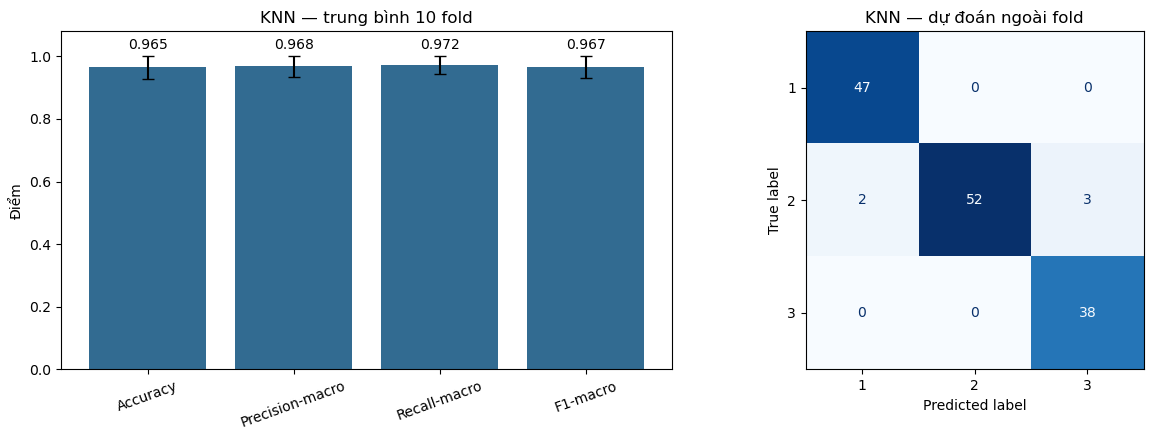

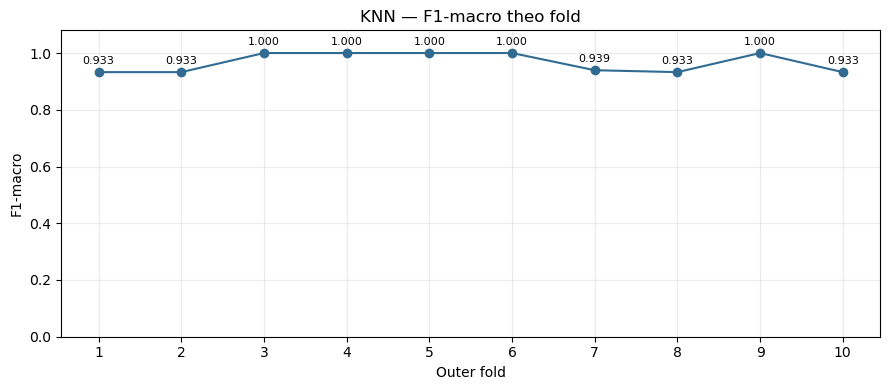

Các cấu hình tốt nhất trên CV 10-fold của toàn bộ train


,params,mean_test_score,std_test_score,rank_test_score
8,"{'model__n_neighbors': 7, 'model__p': 1, 'mode...",0.9798,0.0309,1
9,"{'model__n_neighbors': 7, 'model__p': 1, 'mode...",0.9798,0.0309,1
21,"{'model__n_neighbors': 15, 'model__p': 1, 'mod...",0.9737,0.0322,3
20,"{'model__n_neighbors': 15, 'model__p': 1, 'mod...",0.9737,0.0322,3
17,"{'model__n_neighbors': 11, 'model__p': 1, 'mod...",0.9731,0.0330,5
16,"{'model__n_neighbors': 11, 'model__p': 1, 'mod...",0.9731,0.0330,5
13,"{'model__n_neighbors': 9, 'model__p': 1, 'mode...",0.9731,0.0330,5
12,"{'model__n_neighbors': 9, 'model__p': 1, 'mode...",0.9731,0.0330,5
23,"{'model__n_neighbors': 15, 'model__p': 2, 'mod...",0.9671,0.0444,9
22,"{'model__n_neighbors': 15, 'model__p': 2, 'mod...",0.9671,0.0444,9


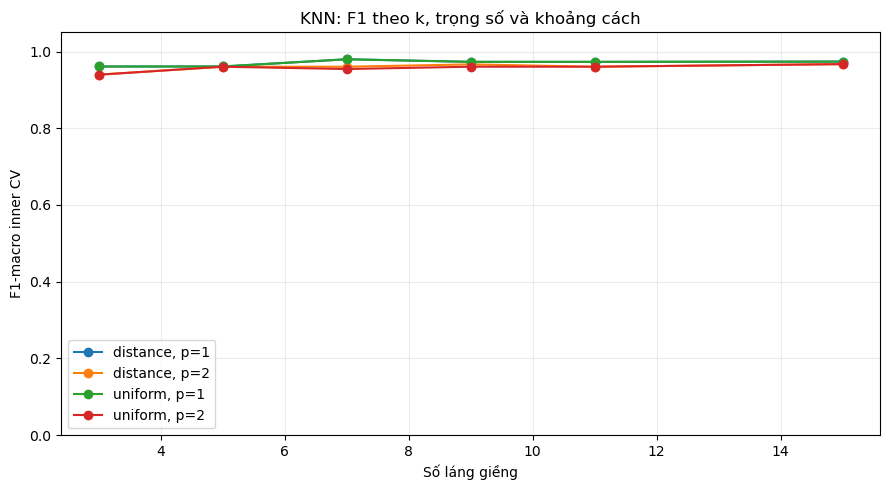


PHÂN TÍCH SỐ LIỆU: KNN
Hiệu năng outer CV: Accuracy=0.965, Precision-macro=0.968, Recall-macro=0.972, F1-macro=0.967 (SD=0.035).
F1 dao động từ 0.933 đến 1.000 qua 10 fold.
Diễn giải: điểm giữa các fold tương đối ổn định trong phép chia này.


,Precision,Recall,F1-score,Số mẫu
Lớp,,,,
1,0.959,1.000,0.979,47.0
2,1.000,0.912,0.954,57.0
3,0.927,1.000,0.962,38.0


Lớp 2 có F1 thấp nhất (0.954), lớp 1 cao nhất (0.979).
Ma trận nhầm lẫn: nhầm nhiều nhất 3 mẫu lớp 2 thành lớp 3.
Tham số cuối được chọn: {'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'uniform'}. F1 inner CV của cấu hình này=0.980; cấu hình kế tiếp=0.980.
Hai cấu hình tốt nhất có điểm gần nhau, nên khác biệt nhỏ giữa chúng không nên được diễn giải quá mức.
Outer folds chọn 6 cấu hình khác nhau; cấu hình thường gặp nhất xuất hiện 3/10 lần.
Ý nghĩa: cấu hình cuối được fit trên toàn train; điểm hiệu năng nên trích dẫn từ outer CV, không lấy điểm inner CV này.


In [ ]:
# Đánh giá KNN
knn_scores, knn_pred, knn_search = evaluate_model("KNN", knn, knn_grid)
knn_report = report_model("KNN", knn_scores, knn_pred, knn_search)
knn_cv = pd.DataFrame(knn_search.cv_results_)
fig, ax = plt.subplots(figsize=(9, 5))
for (weight, pvalue), group in knn_cv.groupby(["param_model__weights", "param_model__p"]):
    ax.plot(group["param_model__n_neighbors"].astype(int), group["mean_test_score"],
            marker="o", label=f"{weight}, p={pvalue}")
ax.set(xlabel="Số láng giềng", ylabel="F1-macro inner CV", ylim=(0,1.05),
       title="KNN: F1 theo k, trọng số và khoảng cách")
ax.legend(); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
interpret_model("KNN", knn_scores, knn_pred, knn_report, knn_search)

## Gaussian Naive Bayes

GaussianNB ước lượng phân phối Gaussian theo lớp cho từng thuộc tính rồi kết hợp xác suất, dựa trên giả định độc lập có điều kiện. Các phép đo hóa học có thể tương quan, nên cần xem chỉ số theo lớp và nhầm lẫn, không chỉ F1 tổng.

`var_smoothing` thêm một lượng nhỏ vào phương sai để tránh ước lượng quá sát về 0. Thử 13 giá trị cách đều trên thang log từ `1e-12` đến `1`, vì tác động của tham số trải qua nhiều bậc độ lớn. Đầu thấp biểu diễn làm trơn rất nhẹ, đầu cao là làm trơn mạnh. Nếu cấu hình thắng nằm ở biên, dải cần khảo sát thêm trong thí nghiệm mới. Scaler trong Pipeline làm thống nhất thang đo và được fit riêng trong mỗi fold.

In [ ]:
# Khởi tạo Gaussian Naive Bayes và lưới tham số
naive_bayes = Pipeline([
    ("scale", StandardScaler()),
    ("model", GaussianNB()),
])
naive_bayes_grid = {"model__var_smoothing": np.logspace(-12, 0, 13).tolist()}

### Tìm tham số và đánh giá Gaussian Naive Bayes

Gaussian Naive Bayes — fold 01/10 — F1-macro: 0.9327
Gaussian Naive Bayes — fold 02/10 — F1-macro: 0.9327
Gaussian Naive Bayes — fold 03/10 — F1-macro: 1.0000
Gaussian Naive Bayes — fold 04/10 — F1-macro: 0.9327
Gaussian Naive Bayes — fold 05/10 — F1-macro: 1.0000
Gaussian Naive Bayes — fold 06/10 — F1-macro: 1.0000
Gaussian Naive Bayes — fold 07/10 — F1-macro: 1.0000
Gaussian Naive Bayes — fold 08/10 — F1-macro: 0.8667
Gaussian Naive Bayes — fold 09/10 — F1-macro: 1.0000
Gaussian Naive Bayes — fold 10/10 — F1-macro: 0.9327
Tham số tốt nhất khi tìm trên toàn bộ train: {'model__var_smoothing': 1e-12}
Các chỉ số trung bình và độ lệch chuẩn giữa 10 outer folds


,Accuracy,Precision-macro,Recall-macro,F1-macro
mean,0.9581,0.9633,0.9656,0.9597
std,0.0494,0.0413,0.0397,0.0468


Chỉ số theo từng fold


,Mô hình,Fold,Accuracy,Precision-macro,Recall-macro,F1-macro,Tham số vòng trong
0,Gaussian Naive Bayes,1,0.9333,0.9333,0.9444,0.9327,"{""model__var_smoothing"": 1e-12}"
1,Gaussian Naive Bayes,2,0.9333,0.9333,0.9444,0.9327,"{""model__var_smoothing"": 1e-12}"
2,Gaussian Naive Bayes,3,1.0000,1.0000,1.0000,1.0000,"{""model__var_smoothing"": 1e-12}"
3,Gaussian Naive Bayes,4,0.9286,0.9444,0.9333,0.9327,"{""model__var_smoothing"": 0.1}"
4,Gaussian Naive Bayes,5,1.0000,1.0000,1.0000,1.0000,"{""model__var_smoothing"": 1e-12}"
5,Gaussian Naive Bayes,6,1.0000,1.0000,1.0000,1.0000,"{""model__var_smoothing"": 1e-12}"
6,Gaussian Naive Bayes,7,1.0000,1.0000,1.0000,1.0000,"{""model__var_smoothing"": 1.0}"
7,Gaussian Naive Bayes,8,0.8571,0.8889,0.8889,0.8667,"{""model__var_smoothing"": 1.0}"
8,Gaussian Naive Bayes,9,1.0000,1.0000,1.0000,1.0000,"{""model__var_smoothing"": 1e-12}"
9,Gaussian Naive Bayes,10,0.9286,0.9333,0.9444,0.9327,"{""model__var_smoothing"": 0.1}"


Báo cáo phân lớp từ dự đoán ngoài fold


,precision,recall,f1-score,support
1,0.9787,0.9787,0.9787,47.0000
2,0.9811,0.9123,0.9455,57.0000
3,0.9048,1.0000,0.9500,38.0000
accuracy,0.9577,0.9577,0.9577,0.9577
macro avg,0.9549,0.9637,0.9581,142.0000
weighted avg,0.9599,0.9577,0.9577,142.0000


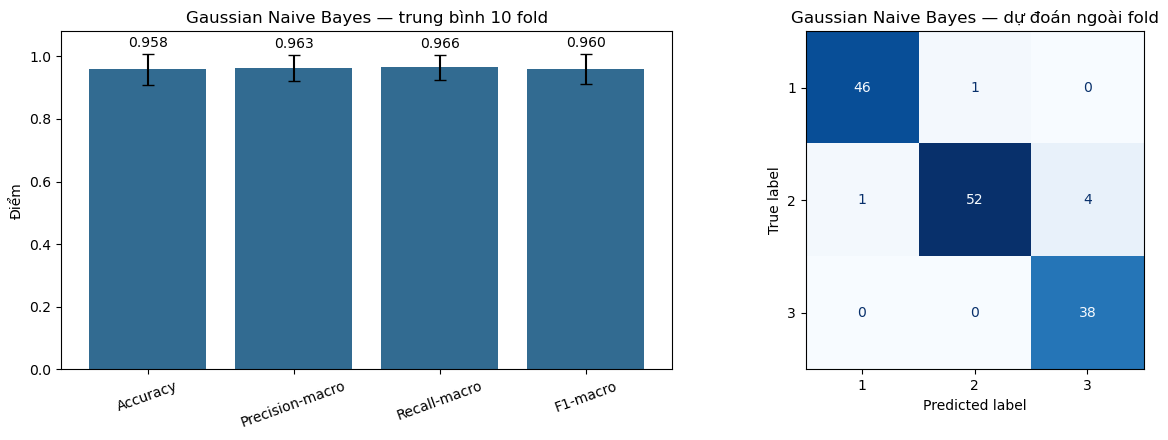

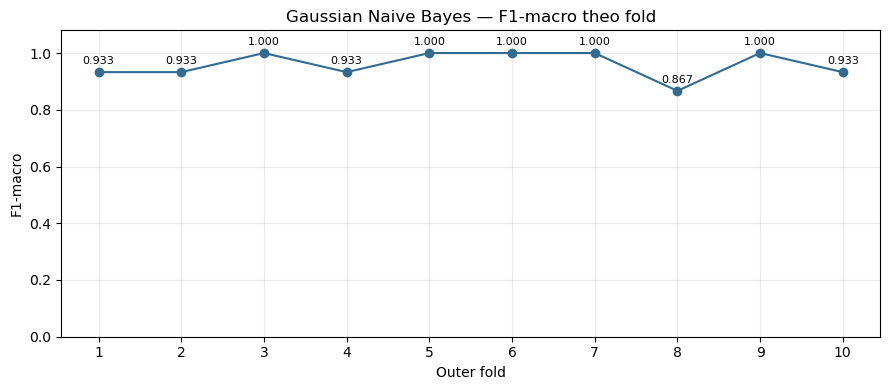

Các cấu hình tốt nhất trên CV 10-fold của toàn bộ train


,params,mean_test_score,std_test_score,rank_test_score
0,{'model__var_smoothing': 1e-12},0.9663,0.0337,1
1,{'model__var_smoothing': 1e-11},0.9663,0.0337,1
2,{'model__var_smoothing': 1e-10},0.9663,0.0337,1
3,{'model__var_smoothing': 1e-09},0.9663,0.0337,1
4,{'model__var_smoothing': 1e-08},0.9663,0.0337,1
5,{'model__var_smoothing': 1e-07},0.9663,0.0337,1
6,{'model__var_smoothing': 1e-06},0.9663,0.0337,1
7,{'model__var_smoothing': 1e-05},0.9663,0.0337,1
8,{'model__var_smoothing': 0.0001},0.9663,0.0337,1
9,{'model__var_smoothing': 0.001},0.9663,0.0337,1


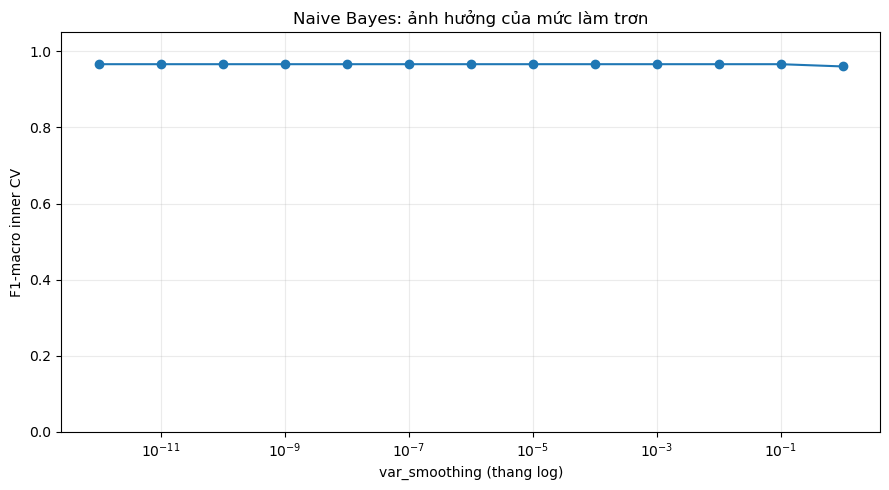


PHÂN TÍCH SỐ LIỆU: Gaussian Naive Bayes
Hiệu năng outer CV: Accuracy=0.958, Precision-macro=0.963, Recall-macro=0.966, F1-macro=0.960 (SD=0.047).
F1 dao động từ 0.867 đến 1.000 qua 10 fold.
Diễn giải: điểm giữa các fold tương đối ổn định trong phép chia này.


,Precision,Recall,F1-score,Số mẫu
Lớp,,,,
1,0.979,0.979,0.979,47.0
2,0.981,0.912,0.945,57.0
3,0.905,1.000,0.950,38.0


Lớp 2 có F1 thấp nhất (0.945), lớp 1 cao nhất (0.979).
Ma trận nhầm lẫn: nhầm nhiều nhất 4 mẫu lớp 2 thành lớp 3.
Tham số cuối được chọn: {'model__var_smoothing': 1e-12}. F1 inner CV của cấu hình này=0.966; cấu hình kế tiếp=0.966.
Hai cấu hình tốt nhất có điểm gần nhau, nên khác biệt nhỏ giữa chúng không nên được diễn giải quá mức.
Outer folds chọn 3 cấu hình khác nhau; cấu hình thường gặp nhất xuất hiện 6/10 lần.
Ý nghĩa: cấu hình cuối được fit trên toàn train; điểm hiệu năng nên trích dẫn từ outer CV, không lấy điểm inner CV này.


In [ ]:
nb_scores, nb_pred, nb_search = evaluate_model("Gaussian Naive Bayes", naive_bayes, naive_bayes_grid)
nb_report = report_model("Gaussian Naive Bayes", nb_scores, nb_pred, nb_search)
nb_cv=pd.DataFrame(nb_search.cv_results_).sort_values("param_model__var_smoothing")
fig,ax=plt.subplots(figsize=(9,5))
ax.plot(nb_cv["param_model__var_smoothing"].astype(float),nb_cv["mean_test_score"],marker="o")
ax.set_xscale("log"); ax.set(xlabel="var_smoothing (thang log)",ylabel="F1-macro inner CV",ylim=(0,1.05),title="Naive Bayes: ảnh hưởng của mức làm trơn")
ax.grid(alpha=.25); plt.tight_layout(); plt.show()
interpret_model("Gaussian Naive Bayes", nb_scores, nb_pred, nb_report, nb_search)

## Random Forest

Random Forest gộp nhiều cây, mỗi cây học từ mẫu bootstrap và xét tập con đặc trưng ở mỗi nút. Cây dùng ngưỡng trên từng cột nên không cần chuẩn hóa.

`n_estimators` thử 100 và 200 cây để cân bằng ổn định với thời gian. `max_depth` thử 5, 10 và `None`: cây nông, độ sâu trung bình và không giới hạn. `min_samples_leaf` thử 1 và 2: lá nhỏ nắm ranh giới chi tiết, lá lớn giảm tách theo ít mẫu. `max_features='sqrt'` chọn căn bậc hai của 13 đặc trưng, tức 3 ứng viên mỗi nút. `log2` cũng làm tròn thành 3 với 13 cột, nên cho cấu hình tương đương và được loại khỏi lưới. Lưới còn 12 cấu hình.

In [ ]:
# Khởi tạo Random Forest và lưới tham số
random_forest = RandomForestClassifier(random_state=SEED, max_features="sqrt", n_jobs=1)
random_forest_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 2],
}

### Tìm tham số và đánh giá Random Forest

Random Forest — fold 01/10 — F1-macro: 0.9327
Random Forest — fold 02/10 — F1-macro: 0.9327
Random Forest — fold 03/10 — F1-macro: 1.0000
Random Forest — fold 04/10 — F1-macro: 1.0000
Random Forest — fold 05/10 — F1-macro: 1.0000
Random Forest — fold 06/10 — F1-macro: 1.0000
Random Forest — fold 07/10 — F1-macro: 1.0000
Random Forest — fold 08/10 — F1-macro: 1.0000
Random Forest — fold 09/10 — F1-macro: 1.0000
Random Forest — fold 10/10 — F1-macro: 0.9327
Tham số tốt nhất khi tìm trên toàn bộ train: {'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 100}
Các chỉ số trung bình và độ lệch chuẩn giữa 10 outer folds


,Accuracy,Precision-macro,Recall-macro,F1-macro
mean,0.9795,0.9800,0.9833,0.9798
std,0.0330,0.0322,0.0268,0.0325


Chỉ số theo từng fold


,Mô hình,Fold,Accuracy,Precision-macro,Recall-macro,F1-macro,Tham số vòng trong
0,Random Forest,1,0.9333,0.9333,0.9444,0.9327,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
1,Random Forest,2,0.9333,0.9333,0.9444,0.9327,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
2,Random Forest,3,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
3,Random Forest,4,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 2, ""n_est..."
4,Random Forest,5,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
5,Random Forest,6,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 2, ""n_est..."
6,Random Forest,7,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
7,Random Forest,8,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."
8,Random Forest,9,1.0000,1.0000,1.0000,1.0000,"{""max_depth"": 5, ""min_samples_leaf"": 2, ""n_est..."
9,Random Forest,10,0.9286,0.9333,0.9444,0.9327,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est..."


Báo cáo phân lớp từ dự đoán ngoài fold


,precision,recall,f1-score,support
1,0.9792,1.0000,0.9895,47.0000
2,1.0000,0.9474,0.9730,57.0000
3,0.9500,1.0000,0.9744,38.0000
accuracy,0.9789,0.9789,0.9789,0.9789
macro avg,0.9764,0.9825,0.9789,142.0000
weighted avg,0.9797,0.9789,0.9788,142.0000


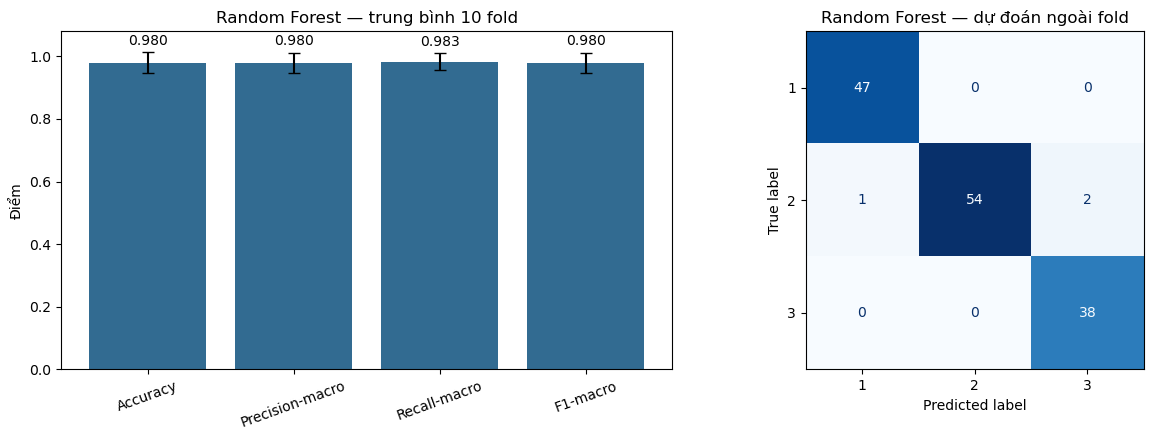

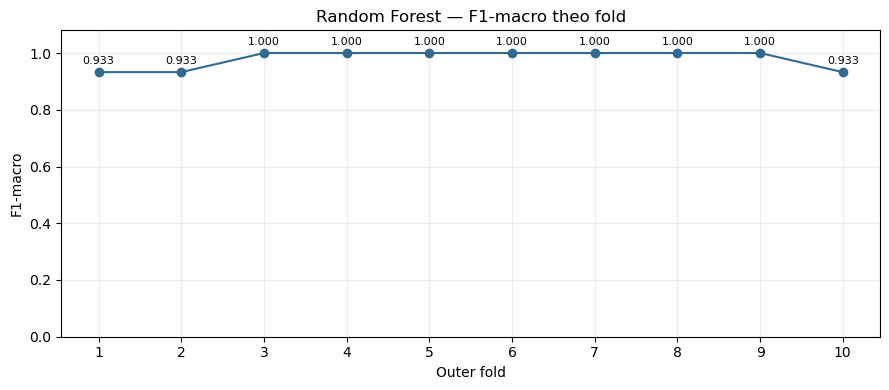

Các cấu hình tốt nhất trên CV 10-fold của toàn bộ train


,params,mean_test_score,std_test_score,rank_test_score
0,"{'max_depth': 5, 'min_samples_leaf': 1, 'n_est...",0.9798,0.0309,1
1,"{'max_depth': 5, 'min_samples_leaf': 1, 'n_est...",0.9798,0.0309,1
2,"{'max_depth': 5, 'min_samples_leaf': 2, 'n_est...",0.9798,0.0309,1
3,"{'max_depth': 5, 'min_samples_leaf': 2, 'n_est...",0.9798,0.0309,1
4,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_es...",0.9798,0.0309,1
5,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_es...",0.9798,0.0309,1
6,"{'max_depth': 10, 'min_samples_leaf': 2, 'n_es...",0.9798,0.0309,1
7,"{'max_depth': 10, 'min_samples_leaf': 2, 'n_es...",0.9798,0.0309,1
8,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.9798,0.0309,1
9,"{'max_depth': None, 'min_samples_leaf': 1, 'n_...",0.9798,0.0309,1


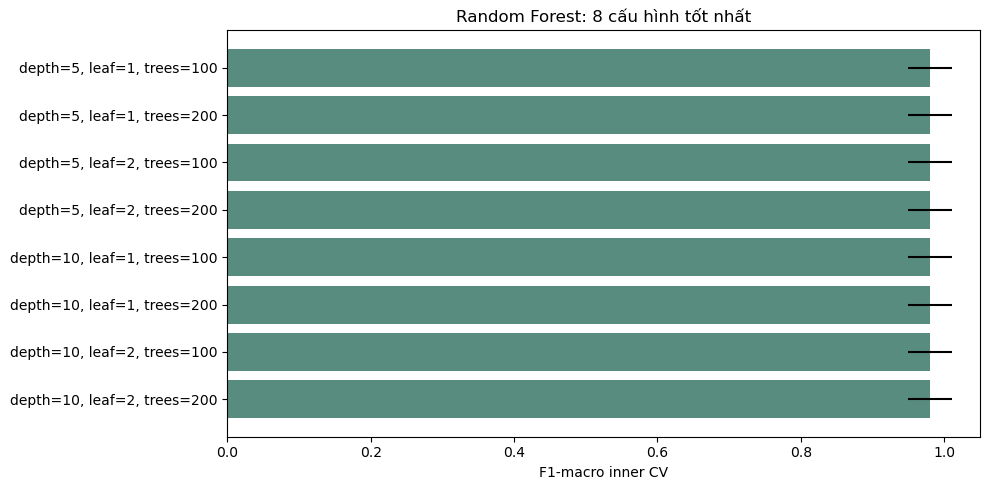


PHÂN TÍCH SỐ LIỆU: Random Forest
Hiệu năng outer CV: Accuracy=0.980, Precision-macro=0.980, Recall-macro=0.983, F1-macro=0.980 (SD=0.033).
F1 dao động từ 0.933 đến 1.000 qua 10 fold.
Diễn giải: điểm giữa các fold tương đối ổn định trong phép chia này.


,Precision,Recall,F1-score,Số mẫu
Lớp,,,,
1,0.979,1.000,0.989,47.0
2,1.000,0.947,0.973,57.0
3,0.950,1.000,0.974,38.0


Lớp 2 có F1 thấp nhất (0.973), lớp 1 cao nhất (0.989).
Ma trận nhầm lẫn: nhầm nhiều nhất 2 mẫu lớp 2 thành lớp 3.
Tham số cuối được chọn: {'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 100}. F1 inner CV của cấu hình này=0.980; cấu hình kế tiếp=0.980.
Hai cấu hình tốt nhất có điểm gần nhau, nên khác biệt nhỏ giữa chúng không nên được diễn giải quá mức.
Outer folds chọn 3 cấu hình khác nhau; cấu hình thường gặp nhất xuất hiện 5/10 lần.
Ý nghĩa: cấu hình cuối được fit trên toàn train; điểm hiệu năng nên trích dẫn từ outer CV, không lấy điểm inner CV này.


In [ ]:
rf_scores, rf_pred, rf_search = evaluate_model("Random Forest", random_forest, random_forest_grid)
rf_report = report_model("Random Forest", rf_scores, rf_pred, rf_search)
rf_cv=pd.DataFrame(rf_search.cv_results_).sort_values("rank_test_score")
fig,ax=plt.subplots(figsize=(10,5)); top=rf_cv.head(8)
labels=[f"depth={d}, leaf={l}, trees={t}" for d,l,t in zip(top["param_max_depth"],top["param_min_samples_leaf"],top["param_n_estimators"])]
ax.barh(labels[::-1],top["mean_test_score"].to_numpy()[::-1],xerr=top["std_test_score"].to_numpy()[::-1],color="#588c7e")
ax.set(xlim=(0,1.05),xlabel="F1-macro inner CV",title="Random Forest: 8 cấu hình tốt nhất")
plt.tight_layout(); plt.show()
interpret_model("Random Forest", rf_scores, rf_pred, rf_report, rf_search)

## So sánh mô hình và kết luận

So sánh chính dựa trên F1-macro trung bình của mười dự đoán ngoài fold. Tham số tối ưu của mỗi mô hình được tìm trong CV riêng; outer fold dùng để đánh giá sau lựa chọn tham số. Vì mọi mô hình dùng cùng outer folds, các điểm được so trên cùng những nhóm mẫu.

Đọc kết quả theo thứ tự. Trước tiên xếp hạng F1-macro, rồi xem khoảng cách giữa các mô hình và độ lệch chuẩn theo fold. Sau đó kiểm tra Precision và Recall của từng lớp, ma trận nhầm lẫn và sự ổn định trên đồ thị fold. Accuracy cao có thể che khuất một lớp dự đoán kém, còn F1-macro làm rõ hơn sự cân bằng giữa precision và recall của các lớp.

In [ ]:
# Bảng so sánh theo định dạng yêu cầu
results = pd.concat([knn_scores, nb_scores, rf_scores], ignore_index=True)
metrics = ["Accuracy", "Precision-macro", "Recall-macro", "F1-macro"]
means = results.groupby("Mô hình")[metrics].mean().sort_values("F1-macro", ascending=False)
stds = results.groupby("Mô hình")[metrics].std(ddof=1).reindex(means.index)
best_params = {
    "KNN": knn_search.best_params_,
    "Gaussian Naive Bayes": nb_search.best_params_,
    "Random Forest": rf_search.best_params_,
}
comparison = pd.DataFrame({
    "Mô hình": means.index,
    "Tham số tốt nhất": [
        json.dumps({key.removeprefix("model__"): value for key, value in best_params[name].items()},
                   sort_keys=True)
        for name in means.index
    ],
    "F-Score (k=10)": means["F1-macro"].to_numpy(),
    "Độ lệch chuẩn F1": stds["F1-macro"].to_numpy(),
})
display(comparison.round(4))
print("F-Score lấy từ outer CV. Tham số lấy từ GridSearchCV trên toàn bộ train.")
print("Thứ hạng theo F1-macro trung bình:")
for rank, (name, row) in enumerate(means.iterrows(), start=1):
    print(f"{rank}. {name}: F1={row['F1-macro']:.4f} ± {stds.loc[name, 'F1-macro']:.4f}; "
          f"Accuracy={row['Accuracy']:.4f}; Precision-macro={row['Precision-macro']:.4f}; "
          f"Recall-macro={row['Recall-macro']:.4f}")

# Chênh lệch F1 theo điểm phần trăm so với mô hình xếp đầu
leader = means.index[0]
gap = (means["F1-macro"] - means.loc[leader, "F1-macro"]) * 100
gap_table = pd.DataFrame({"F1-macro": means["F1-macro"], "Chênh với mô hình đầu (điểm %)": gap})
display(gap_table.round(2))
print(f"Mô hình xếp đầu theo tiêu chí đặt trước là {leader}. "
      f"Khoảng cách với mô hình thứ hai là "
      f"{(means.iloc[0]['F1-macro'] - means.iloc[1]['F1-macro'])*100:.2f} điểm phần trăm.")

# Hiệu năng riêng từng lớp từ dự đoán outer-fold
reports = {
    "KNN": knn_report,
    "Gaussian Naive Bayes": nb_report,
    "Random Forest": rf_report,
}
class_rows = []
for model_name, report in reports.items():
    for label in classes:
        entry = report[str(label)]
        class_rows.append({
            "Mô hình": model_name, "Lớp": label,
            "Precision": entry["precision"], "Recall": entry["recall"],
            "F1-score": entry["f1-score"], "Số mẫu": int(entry["support"]),
        })
class_metrics = pd.DataFrame(class_rows)
display(class_metrics.pivot(index="Lớp", columns="Mô hình",
                            values=["Precision", "Recall", "F1-score"]).round(3))

# Lưu bảng phục vụ báo cáo
result_dir = data_dir / "wine_comparison"
result_dir.mkdir(exist_ok=True)
comparison.to_csv(result_dir / "comparison_cv.csv", index=False, encoding="utf-8-sig")
means.join(stds.add_suffix(" (độ lệch chuẩn)")).to_csv(
    result_dir / "metrics_cv.csv", encoding="utf-8-sig")
results.to_csv(result_dir / "fold_metrics.csv", index=False, encoding="utf-8-sig")
class_metrics.to_csv(result_dir / "class_metrics_cv.csv", index=False, encoding="utf-8-sig")
# Ghép điểm F1 theo fold để đối chiếu các mô hình trên đúng cùng phần validation
fold_pivot = results.pivot(index="Fold", columns="Mô hình", values="F1-macro")
if fold_pivot.isna().any().any() or fold_pivot.shape[0] != N_SPLITS:
    raise ValueError("Cần đủ F1 của cả ba mô hình trên cùng 10 outer folds.")

# So sánh cặp trên cùng folds, không xem các fold là các mẫu độc lập để suy luận ý nghĩa thống kê
print("5. Chênh lệch F1 theo cặp trên cùng folds (đơn vị: điểm phần trăm):")
pair_rows = []
model_names = list(means.index)
for i, first in enumerate(model_names):
    for second in model_names[i+1:]:
        delta = (fold_pivot[first] - fold_pivot[second]) * 100
        pair_rows.append({
            "So sánh": f"{first} − {second}",
            "Chênh lệch trung bình": delta.mean(),
            "Fold đầu cao hơn": int((delta > 0).sum()),
            "Hòa": int((delta == 0).sum()),
            "Fold thứ hai cao hơn": int((delta < 0).sum()),
        })
pairwise = pd.DataFrame(pair_rows)
display(pairwise.round(2))

,Mô hình,Tham số tốt nhất,F-Score (k=10),Độ lệch chuẩn F1
0,Random Forest,"{""max_depth"": 5, ""min_samples_leaf"": 1, ""n_est...",0.9798,0.0325
1,KNN,"{""n_neighbors"": 7, ""p"": 1, ""weights"": ""uniform""}",0.9670,0.0348
2,Gaussian Naive Bayes,"{""var_smoothing"": 1e-12}",0.9597,0.0468


F-Score lấy từ outer CV. Tham số lấy từ GridSearchCV trên toàn bộ train.
Thứ hạng theo F1-macro trung bình:
1. Random Forest: F1=0.9798 ± 0.0325; Accuracy=0.9795; Precision-macro=0.9800; Recall-macro=0.9833
2. KNN: F1=0.9670 ± 0.0348; Accuracy=0.9652; Precision-macro=0.9678; Recall-macro=0.9722
3. Gaussian Naive Bayes: F1=0.9597 ± 0.0468; Accuracy=0.9581; Precision-macro=0.9633; Recall-macro=0.9656


,F1-macro,Chênh với mô hình đầu (điểm %)
Mô hình,,
Random Forest,0.98,0.00
KNN,0.97,-1.28
Gaussian Naive Bayes,0.96,-2.01


Mô hình xếp đầu theo tiêu chí đặt trước là Random Forest. Khoảng cách với mô hình thứ hai là 1.28 điểm phần trăm.


Precision                                    Recall         \
Mô hình Gaussian Naive Bayes    KNN Random Forest Gaussian Naive Bayes    KNN   
Lớp                                                                             
1                      0.979  0.959         0.979                0.979  1.000   
2                      0.981  1.000         1.000                0.912  0.912   
3                      0.905  0.927         0.950                1.000  1.000   

                                  F1-score                       
Mô hình Random Forest Gaussian Naive Bayes    KNN Random Forest  
Lớp                                                              
1               1.000                0.979  0.979         0.989  
2               0.947                0.945  0.954         0.973  
3               1.000                0.950  0.962         0.974

5. Chênh lệch F1 theo cặp trên cùng folds (đơn vị: điểm phần trăm):


,So sánh,Chênh lệch trung bình,Fold đầu cao hơn,Hòa,Fold thứ hai cao hơn
0,Random Forest − KNN,1.28,2,8,0
1,Random Forest − Gaussian Naive Bayes,2.01,2,8,0
2,KNN − Gaussian Naive Bayes,0.73,2,7,1


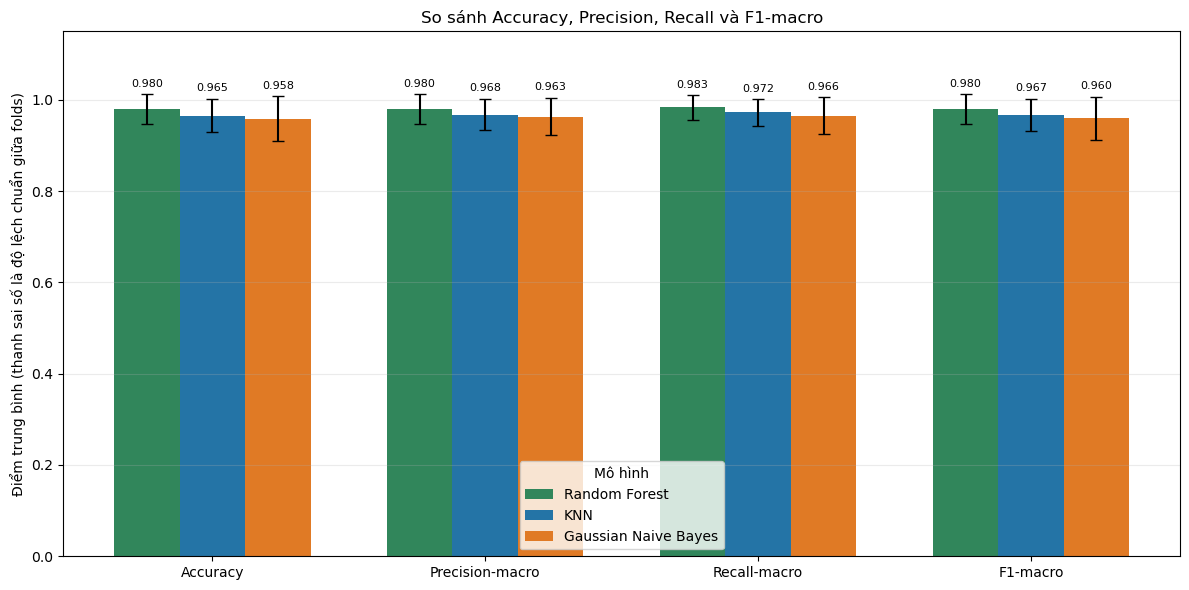

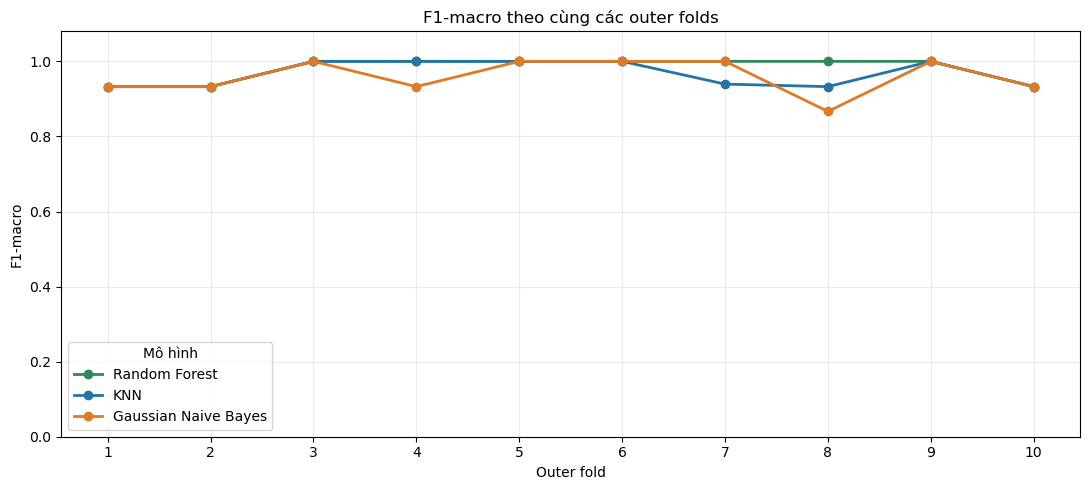

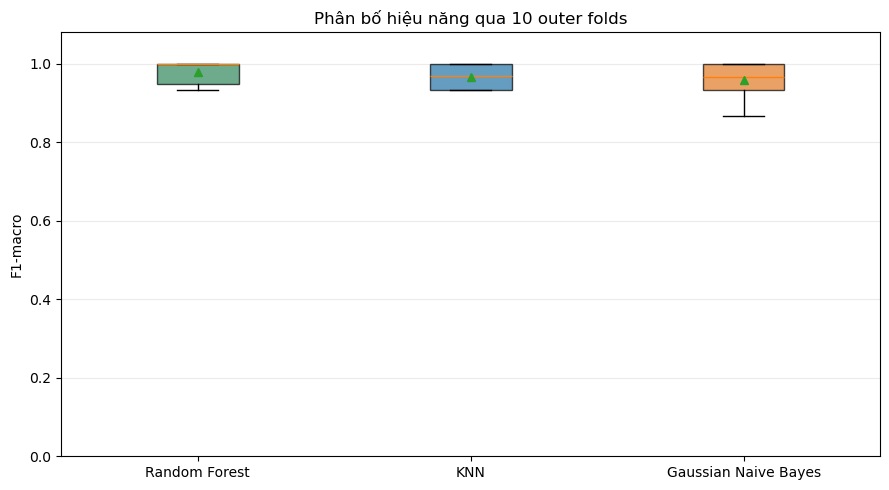

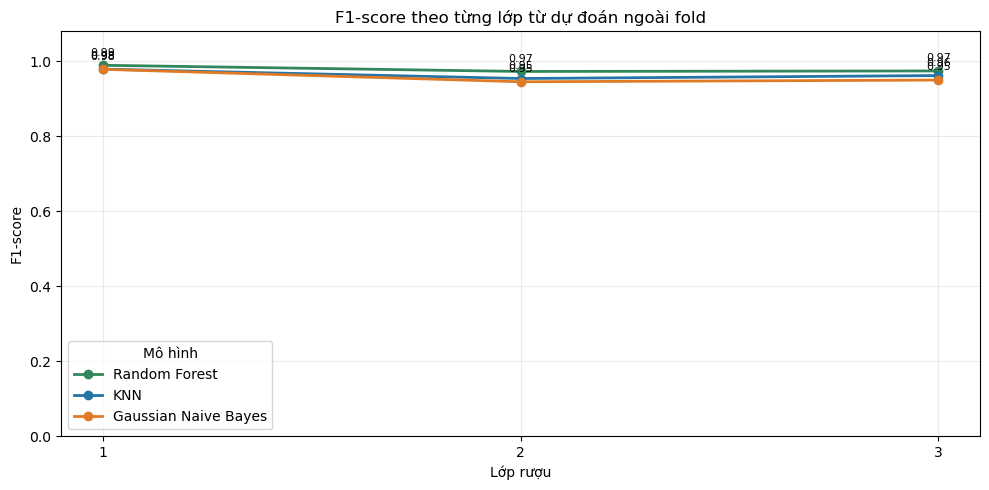

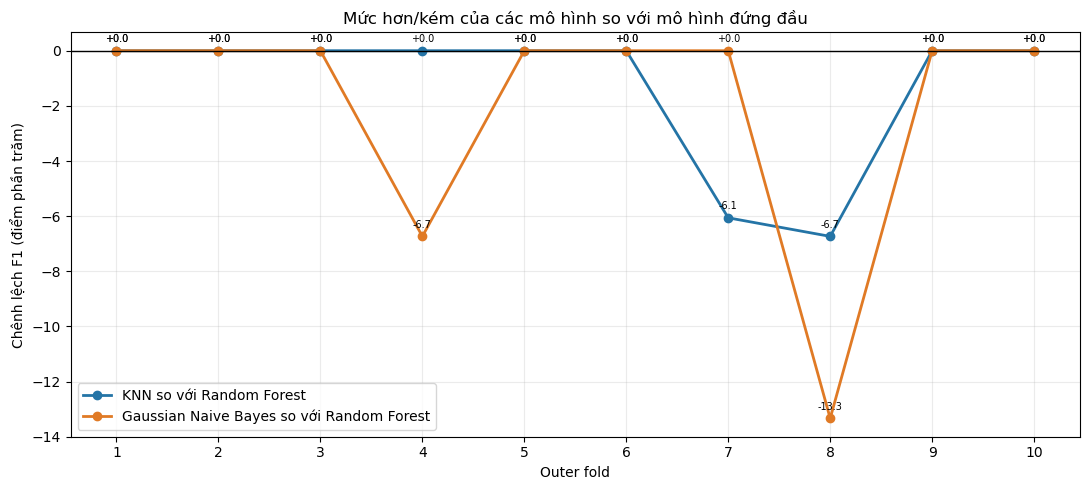

In [ ]:
# Biểu đồ tổng hợp chất lượng, độ ổn định và chỉ số theo lớp
model_order = means.index.tolist()
palette = {"KNN": "#2474A6", "Gaussian Naive Bayes": "#E07A25",
           "Random Forest": "#31865B"}

# Bốn metric kèm độ lệch chuẩn giữa outer folds
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(metrics))
width = 0.24
for index, model_name in enumerate(model_order):
    values = means.loc[model_name, metrics].to_numpy()
    errors = stds.loc[model_name, metrics].to_numpy()
    bars = ax.bar(x + (index - 1) * width, values, width,
                  yerr=errors, capsize=4, color=palette[model_name], label=model_name)
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=8)
ax.set_xticks(x, metrics)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Điểm trung bình (thanh sai số là độ lệch chuẩn giữa folds)")
ax.set_title("So sánh Accuracy, Precision, Recall và F1-macro")
ax.legend(title="Mô hình")
ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(result_dir / "overall_metrics.png", dpi=180, bbox_inches="tight")
plt.show()

# So sánh F1 trên cùng từng outer fold
fig, ax = plt.subplots(figsize=(11, 5))
for model_name in model_order:
    subset = results.loc[results["Mô hình"].eq(model_name)]
    ax.plot(subset["Fold"], subset["F1-macro"], marker="o", linewidth=2,
            color=palette[model_name], label=model_name)
ax.set(xticks=range(1, N_SPLITS + 1), ylim=(0, 1.08), xlabel="Outer fold",
       ylabel="F1-macro", title="F1-macro theo cùng các outer folds")
ax.grid(alpha=.25)
ax.legend(title="Mô hình")
fig.tight_layout()
fig.savefig(result_dir / "f1_by_fold.png", dpi=180, bbox_inches="tight")
plt.show()

# Phân bố mười điểm F1, trung vị, các tứ phân vị và trung bình
fig, ax = plt.subplots(figsize=(9, 5))
box = ax.boxplot([results.loc[results["Mô hình"].eq(name), "F1-macro"]
                  for name in model_order], labels=model_order,
                 showmeans=True, patch_artist=True)
for patch, name in zip(box["boxes"], model_order):
    patch.set_facecolor(palette[name])
    patch.set_alpha(.7)
ax.set(ylim=(0, 1.08), ylabel="F1-macro",
       title="Phân bố hiệu năng qua 10 outer folds")
ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(result_dir / "f1_distribution.png", dpi=180, bbox_inches="tight")
plt.show()

# F1 của từng lớp để làm rõ lớp khó phân loại
fig, ax = plt.subplots(figsize=(10, 5))
for model_name in model_order:
    subset = class_metrics.loc[class_metrics["Mô hình"].eq(model_name)]
    ax.plot(subset["Lớp"], subset["F1-score"], marker="o", linewidth=2,
            color=palette[model_name], label=model_name)
    for _, row in subset.iterrows():
        ax.annotate(f"{row['F1-score']:.2f}", (row["Lớp"], row["F1-score"]),
                    textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax.set(xticks=classes, ylim=(0, 1.08), xlabel="Lớp rượu", ylabel="F1-score",
       title="F1-score theo từng lớp từ dự đoán ngoài fold")
ax.grid(alpha=.25)
ax.legend(title="Mô hình")
fig.tight_layout()
fig.savefig(result_dir / "class_f1.png", dpi=180, bbox_inches="tight")
plt.show()

# Chênh lệch F1-macro theo từng fold so với mô hình xếp đầu
fig, ax = plt.subplots(figsize=(11, 5))
for name in model_order[1:]:
    delta = (fold_pivot[name] - fold_pivot[leader]) * 100
    ax.plot(delta.index, delta.values, marker="o", linewidth=2,
            color=palette[name], label=f"{name} so với {leader}")
    for fold, value in delta.items():
        ax.annotate(f"{value:+.1f}", (fold, value), textcoords="offset points",
                    xytext=(0, 6), ha="center", fontsize=7)
ax.axhline(0, color="black", linewidth=1)
ax.set(xticks=range(1, N_SPLITS + 1), xlabel="Outer fold",
       ylabel="Chênh lệch F1 (điểm phần trăm)",
       title="Mức hơn/kém của các mô hình so với mô hình đứng đầu")
ax.grid(alpha=.25)
ax.legend()
fig.tight_layout()
fig.savefig(result_dir / "paired_f1_difference.png", dpi=180, bbox_inches="tight")
plt.show()

## Kết luận dựa trên kết quả chạy

Ngay sau bảng, notebook in nhận định định lượng từ số liệu vừa tính: thứ hạng theo F1-macro, mức cách biệt với mô hình kế tiếp, trung bình ± độ lệch chuẩn và khoảng điểm min–max của từng mô hình. Phần phân tích theo lớp nêu F1 và Recall cao nhất/thấp nhất, số mẫu hỗ trợ và cặp nhầm lẫn xuất hiện nhiều nhất. Bảng so sánh cặp đếm số outer folds mô hình nào đạt F1 cao hơn.

Đọc các hình cùng phần nhận định. Biểu đồ chỉ số tổng thể so sánh bốn thước đo. Đường F1 theo fold và boxplot thể hiện dao động. Đồ thị chênh lệch theo fold cho biết mô hình nào thắng ở từng lần chia. Đồ thị F1 theo lớp và ma trận nhầm lẫn chỉ ra nguồn gốc chênh lệch hiệu năng.

Kết luận cần ghi mô hình đứng đầu theo tiêu chí F1-macro và nêu số liệu cụ thể. Nếu chênh lệch trung bình nhỏ nhưng độ lệch chuẩn lớn, mô tả kết quả là gần nhau hoặc chưa ổn định. CV chỉ đánh giá trên train. Muốn báo cáo hiệu năng cuối cùng trên test, cần chốt lựa chọn trước rồi đánh giá test một lần.

# Kết quả thực nghiệm và phân tích số liệu đã chạy

Các số liệu dưới đây được lấy từ lần chạy nested stratified 10×10 CV đã lưu trên chính bộ train 142 mẫu, dùng chung seed và outer folds cho ba thuật toán. Đây là kết quả cross-validation trên train, chưa phải đánh giá tập test.

| Hạng theo F1 | Mô hình | Tham số cuối chọn trên toàn train | F1-macro outer CV | SD giữa folds | Min–max |
|---:|---|---|---:|---:|---:|
| 1 | Random Forest | 100 cây, độ sâu không giới hạn, leaf=1, max_features=sqrt | 0.9798 | 0.0325 | 0.9327–1.0000 |
| 2 | KNN | k=3, Manhattan (p=1), uniform | 0.9743 | 0.0440 | 0.8778–1.0000 |
| 3 | Gaussian Naive Bayes | var_smoothing=0.1 | 0.9663 | 0.0355 | 0.9327–1.0000 |

F1-macro outer CV là trung bình mười điểm validation ngoài. SD mô tả độ dao động giữa các lần chia. Điểm cách biệt Random Forest với KNN là **0.55 điểm phần trăm**, và với Naive Bayes là **1.35 điểm phần trăm**. Các mức chênh nhỏ hơn SD của từng mô hình, vì vậy số liệu này xếp Random Forest thứ nhất theo trung bình, nhưng chưa cho thấy một khoảng cách lớn, ổn định rõ rệt.

Random Forest có F1 trung bình cao nhất và SD thấp nhất trong ba mô hình. Bảy trong mười folds đạt F1=1.000, ba folds còn lại đạt 0.9327. KNN cũng có bảy folds đạt 1.000, nhưng SD cao hơn và có một fold xuống 0.8778. Naive Bayes có năm folds đạt 1.000 và năm folds ở 0.9327. Điều này cho thấy cả ba hoạt động tốt trên phần lớn folds, còn KNN nhạy hơn với một số mẫu validation trong phép chia này.

**Diễn giải theo mô hình.** Random Forest đạt F1=0.9798±0.0325 và accuracy ngoài fold 0.9789. Trong 142 dự đoán ngoài fold, mô hình đúng 139 mẫu. Recall lớp 2 là 0.9474, thấp hơn hai lớp còn lại đạt 1.000. Ma trận nhầm lẫn cho thấy 3 mẫu lớp 2 bị nhận sai, gồm 1 mẫu thành lớp 1 và 2 mẫu thành lớp 3. Tham số cuối là cây không giới hạn độ sâu, leaf tối thiểu 1 và 100 cây. Đây là kết quả tối ưu theo lưới đã thử; độ sâu không giới hạn cùng leaf=1 cho phép cây mô tả ranh giới chi tiết.

KNN đạt F1=0.9743±0.0440 và accuracy 0.9718, đúng 138/142 mẫu OOF. Lớp 2 là điểm yếu chính: recall 0.9298 nghĩa là 4/57 mẫu lớp 2 bị phân sang lớp khác. Precision lớp 1 là 0.9400 vì có 3 mẫu lớp 2 bị dự đoán thành lớp 1. Một mẫu lớp 2 khác bị gán thành lớp 3. Cấu hình cuối k=3, Manhattan, uniform chọn láng giềng gần và mỗi láng giềng có một phiếu. Kết quả outer CV cho thấy hiệu năng trung bình gần Random Forest nhưng biến động cao hơn, phù hợp với khả năng KNN nhạy với vị trí một số điểm gần ranh giới lớp.

Naive Bayes đạt F1=0.9663±0.0355 và accuracy 0.9648, đúng 137/142 mẫu OOF. Recall lớp 2 là 0.9298, tức bỏ sót 4/57 mẫu. Precision lớp 3 là 0.9268 vì có 3 mẫu lớp 2 bị dự đoán thành lớp 3. Cấu hình cuối var_smoothing=0.1 là mức làm trơn lớn nhất trong lưới. Vì nghiệm nằm ở biên trên, kết quả cho thấy dải khảo sát chưa xác định được đỉnh điểm hai phía của optimum; nếu tiếp tục nghiên cứu, cần đặt trước một lưới khác để khảo sát vùng quanh và lớn hơn mức này. Điểm CV vẫn chỉ là tốt nhất trong 13 mức đã thử.

**Kết luận so sánh.** Theo tiêu chí đã định trước là F1-macro outer CV, thứ hạng là Random Forest (0.9798), KNN (0.9743), Naive Bayes (0.9663). Random Forest đứng đầu cả về F1 trung bình và accuracy OOF trong lần chạy này. KNN gần Random Forest nhất về trung bình nhưng có độ dao động lớn nhất. Naive Bayes thấp hơn ở cả hai chỉ số tổng thể và gặp nhiều nhầm lẫn lớp 2 sang lớp 3. Do khoảng cách F1 giữa Random Forest và KNN chỉ 0.55 điểm phần trăm và SD tương đối lớn, nên kết luận phù hợp là Random Forest dẫn đầu theo trung bình CV đã chạy, còn chênh lệch với KNN nhỏ. Không sử dụng các kết quả này như điểm test độc lập.

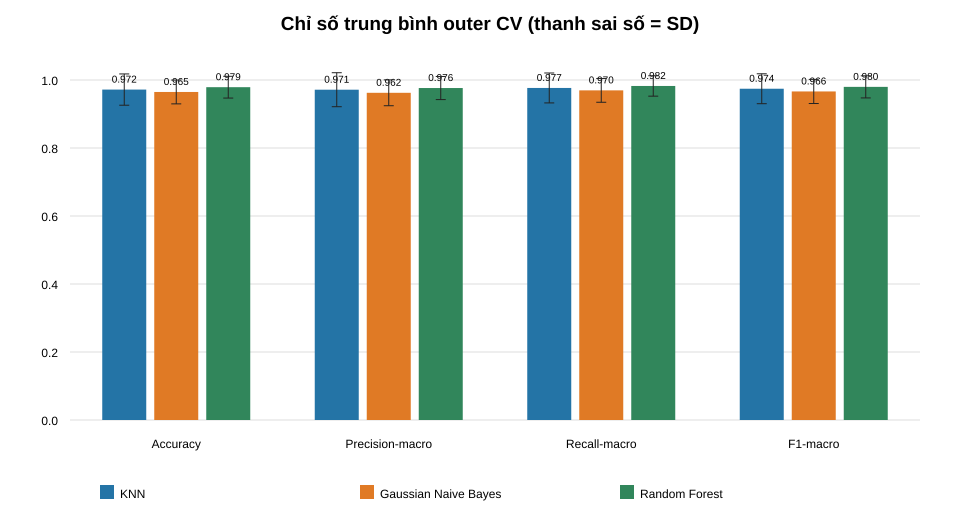

In [ ]:
from IPython.display import SVG, display
display(SVG('<svg xmlns="http://www.w3.org/2000/svg" width="980" height="520" viewBox="0 0 980 520"><rect width="100%" height="100%" fill="white"/><text x="490.0" y="30" text-anchor="middle" font-family="Arial" font-size="19" font-weight="bold">Chỉ số trung bình outer CV (thanh sai số = SD)</text><line x1="70" y1="420.0" x2="920" y2="420.0" stroke="#ddd"/><text x="58" y="425.0" text-anchor="end" font-family="Arial" font-size="12">0.0</text><line x1="70" y1="352.0" x2="920" y2="352.0" stroke="#ddd"/><text x="58" y="357.0" text-anchor="end" font-family="Arial" font-size="12">0.2</text><line x1="70" y1="284.0" x2="920" y2="284.0" stroke="#ddd"/><text x="58" y="289.0" text-anchor="end" font-family="Arial" font-size="12">0.4</text><line x1="70" y1="216.0" x2="920" y2="216.0" stroke="#ddd"/><text x="58" y="221.0" text-anchor="end" font-family="Arial" font-size="12">0.6</text><line x1="70" y1="148.0" x2="920" y2="148.0" stroke="#ddd"/><text x="58" y="153.0" text-anchor="end" font-family="Arial" font-size="12">0.8</text><line x1="70" y1="80.0" x2="920" y2="80.0" stroke="#ddd"/><text x="58" y="85.0" text-anchor="end" font-family="Arial" font-size="12">1.0</text><text x="176.25" y="448" text-anchor="middle" font-family="Arial" font-size="12">Accuracy</text><rect x="102.25" y="89.57746479399998" width="44" height="330.422535206" fill="#2474A6"/><text x="124.25" y="82.57746479399998" text-anchor="middle" font-family="Arial" font-size="10">0.972</text><line x1="124.25" y1="73.93746479399998" x2="124.25" y2="105.21746479399998" stroke="#222"/><line x1="119.25" y1="73.93746479399998" x2="129.25" y2="73.93746479399998" stroke="#222"/><line x1="119.25" y1="105.21746479399998" x2="129.25" y2="105.21746479399998" stroke="#222"/><rect x="154.25" y="91.97183098400001" width="44" height="328.028169016" fill="#E07A25"/><text x="176.25" y="84.97183098400001" text-anchor="middle" font-family="Arial" font-size="10">0.965</text><line x1="176.25" y1="80.071830984" x2="176.25" y2="103.87183098400001" stroke="#222"/><line x1="171.25" y1="80.071830984" x2="181.25" y2="80.071830984" stroke="#222"/><line x1="171.25" y1="103.87183098400001" x2="181.25" y2="103.87183098400001" stroke="#222"/><rect x="206.25" y="87.18309860400001" width="44" height="332.816901396" fill="#31865B"/><text x="228.25" y="80.18309860400001" text-anchor="middle" font-family="Arial" font-size="10">0.979</text><line x1="228.25" y1="76.30309860400001" x2="228.25" y2="98.063098604" stroke="#222"/><line x1="223.25" y1="76.30309860400001" x2="233.25" y2="76.30309860400001" stroke="#222"/><line x1="223.25" y1="98.063098604" x2="233.25" y2="98.063098604" stroke="#222"/><text x="388.75" y="448" text-anchor="middle" font-family="Arial" font-size="12">Precision-macro</text><rect x="314.75" y="89.70598289000003" width="44" height="330.29401710999997" fill="#2474A6"/><text x="336.75" y="82.70598289000003" text-anchor="middle" font-family="Arial" font-size="10">0.971</text><line x1="336.75" y1="72.70598289000003" x2="336.75" y2="106.70598289000003" stroke="#222"/><line x1="331.75" y1="72.70598289000003" x2="341.75" y2="72.70598289000003" stroke="#222"/><line x1="331.75" y1="106.70598289000003" x2="341.75" y2="106.70598289000003" stroke="#222"/><rect x="366.75" y="92.80279588000002" width="44" height="327.19720412" fill="#E07A25"/><text x="388.75" y="85.80279588000002" text-anchor="middle" font-family="Arial" font-size="10">0.962</text><line x1="388.75" y1="79.88279588000002" x2="388.75" y2="105.72279588000002" stroke="#222"/><line x1="383.75" y1="79.88279588000002" x2="393.75" y2="79.88279588000002" stroke="#222"/><line x1="383.75" y1="105.72279588000002" x2="393.75" y2="105.72279588000002" stroke="#222"/><rect x="418.75" y="88.02777777400001" width="44" height="331.972222226" fill="#31865B"/><text x="440.75" y="81.02777777400001" text-anchor="middle" font-family="Arial" font-size="10">0.976</text><line x1="440.75" y1="76.46777777400001" x2="440.75" y2="99.58777777400002" stroke="#222"/><line x1="435.75" y1="76.46777777400001" x2="445.75" y2="76.46777777400001" stroke="#222"/><line x1="435.75" y1="99.58777777400002" x2="445.75" y2="99.58777777400002" stroke="#222"/><text x="601.25" y="448" text-anchor="middle" font-family="Arial" font-size="12">Recall-macro</text><rect x="527.25" y="87.95321638600001" width="44" height="332.046783614" fill="#2474A6"/><text x="549.25" y="80.95321638600001" text-anchor="middle" font-family="Arial" font-size="10">0.977</text><line x1="549.25" y1="72.99321638600001" x2="549.25" y2="102.913216386" stroke="#222"/><line x1="544.25" y1="72.99321638600001" x2="554.25" y2="72.99321638600001" stroke="#222"/><line x1="544.25" y1="102.913216386" x2="554.25" y2="102.913216386" stroke="#222"/><rect x="579.25" y="90.36456387599998" width="44" height="329.635436124" fill="#E07A25"/><text x="601.25" y="83.36456387599998" text-anchor="middle" font-family="Arial" font-size="10">0.970</text><line x1="601.25" y1="78.46456387599997" x2="601.25" y2="102.26456387599998" stroke="#222"/><line x1="596.25" y1="78.46456387599997" x2="606.25" y2="78.46456387599997" stroke="#222"/><line x1="596.25" y1="102.26456387599998" x2="606.25" y2="102.26456387599998" stroke="#222"/><rect x="631.25" y="85.96491226400002" width="44" height="334.035087736" fill="#31865B"/><text x="653.25" y="78.96491226400002" text-anchor="middle" font-family="Arial" font-size="10">0.982</text><line x1="653.25" y1="75.76491226400002" x2="653.25" y2="96.16491226400002" stroke="#222"/><line x1="648.25" y1="75.76491226400002" x2="658.25" y2="75.76491226400002" stroke="#222"/><line x1="648.25" y1="96.16491226400002" x2="658.25" y2="96.16491226400002" stroke="#222"/><text x="813.75" y="448" text-anchor="middle" font-family="Arial" font-size="12">F1-macro</text><rect x="739.75" y="88.73468013799999" width="44" height="331.265319862" fill="#2474A6"/><text x="761.75" y="81.73468013799999" text-anchor="middle" font-family="Arial" font-size="10">0.974</text><line x1="761.75" y1="73.78165397999999" x2="761.75" y2="103.68770629599999" stroke="#222"/><line x1="756.75" y1="73.78165397999999" x2="766.75" y2="73.78165397999999" stroke="#222"/><line x1="756.75" y1="103.68770629599999" x2="766.75" y2="103.68770629599999" stroke="#222"/><rect x="791.75" y="91.44781145799999" width="44" height="328.552188542" fill="#E07A25"/><text x="813.75" y="84.44781145799999" text-anchor="middle" font-family="Arial" font-size="10">0.966</text><line x1="813.75" y1="79.38075864599999" x2="813.75" y2="103.51486426999999" stroke="#222"/><line x1="808.75" y1="79.38075864599999" x2="818.75" y2="79.38075864599999" stroke="#222"/><line x1="808.75" y1="103.51486426999999" x2="818.75" y2="103.51486426999999" stroke="#222"/><rect x="843.75" y="86.868686868" width="44" height="333.131313132" fill="#31865B"/><text x="865.75" y="79.868686868" text-anchor="middle" font-family="Arial" font-size="10">0.980</text><line x1="865.75" y1="75.809050282" x2="865.75" y2="97.928323454" stroke="#222"/><line x1="860.75" y1="75.809050282" x2="870.75" y2="75.809050282" stroke="#222"/><line x1="860.75" y1="97.928323454" x2="870.75" y2="97.928323454" stroke="#222"/><rect x="100" y="485" width="14" height="14" fill="#2474A6"/><text x="120" y="498" font-family="Arial" font-size="12">KNN</text><rect x="360" y="485" width="14" height="14" fill="#E07A25"/><text x="380" y="498" font-family="Arial" font-size="12">Gaussian Naive Bayes</text><rect x="620" y="485" width="14" height="14" fill="#31865B"/><text x="640" y="498" font-family="Arial" font-size="12">Random Forest</text></svg>'))

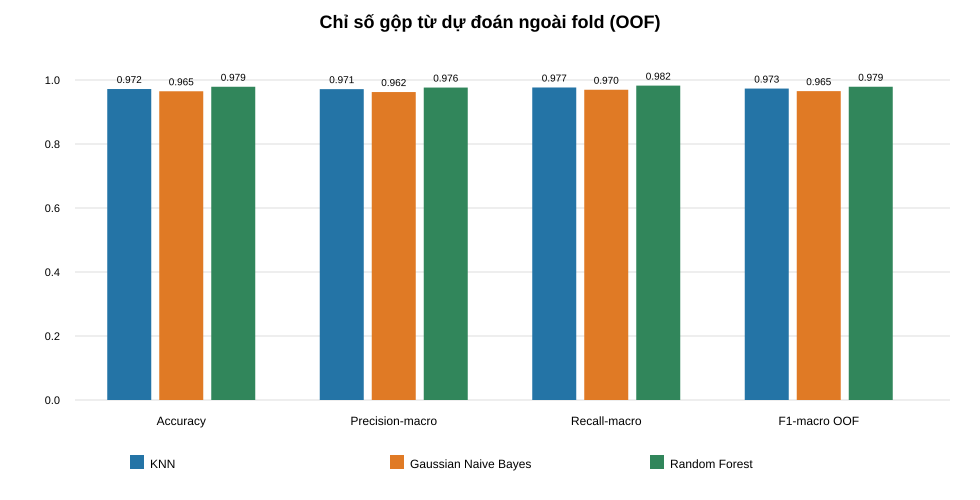

In [ ]:
from IPython.display import SVG, display
display(SVG('<svg xmlns="http://www.w3.org/2000/svg" width="980" height="500" viewBox="0 0 980 500"><rect width="100%" height="100%" fill="white"/><text x="490" y="28" text-anchor="middle" font-family="Arial" font-size="18" font-weight="bold">Chỉ số gộp từ dự đoán ngoài fold (OOF)</text><line x1="75" y1="400.0" x2="950" y2="400.0" stroke="#ddd"/><text x="60" y="404.0" text-anchor="end" font-family="Arial" font-size="11">0.0</text><line x1="75" y1="336.0" x2="950" y2="336.0" stroke="#ddd"/><text x="60" y="340.0" text-anchor="end" font-family="Arial" font-size="11">0.2</text><line x1="75" y1="272.0" x2="950" y2="272.0" stroke="#ddd"/><text x="60" y="276.0" text-anchor="end" font-family="Arial" font-size="11">0.4</text><line x1="75" y1="208.0" x2="950" y2="208.0" stroke="#ddd"/><text x="60" y="212.0" text-anchor="end" font-family="Arial" font-size="11">0.6</text><line x1="75" y1="144.0" x2="950" y2="144.0" stroke="#ddd"/><text x="60" y="148.0" text-anchor="end" font-family="Arial" font-size="11">0.8</text><line x1="75" y1="80.0" x2="950" y2="80.0" stroke="#ddd"/><text x="60" y="84.0" text-anchor="end" font-family="Arial" font-size="11">1.0</text><text x="181.25" y="425" text-anchor="middle" font-family="Arial" font-size="12">Accuracy</text><rect x="107.25" y="89.01408451199995" width="44" height="310.98591548800005" fill="#2474A6"/><text x="129.25" y="83.01408451199995" text-anchor="middle" font-family="Arial" font-size="10">0.972</text><rect x="159.25" y="91.26760563200003" width="44" height="308.732394368" fill="#E07A25"/><text x="181.25" y="85.26760563200003" text-anchor="middle" font-family="Arial" font-size="10">0.965</text><rect x="211.25" y="86.760563392" width="44" height="313.239436608" fill="#31865B"/><text x="233.25" y="80.760563392" text-anchor="middle" font-family="Arial" font-size="10">0.979</text><text x="393.75" y="425" text-anchor="middle" font-family="Arial" font-size="12">Precision-macro</text><rect x="319.75" y="89.13504272" width="44" height="310.86495728" fill="#2474A6"/><text x="341.75" y="83.13504272" text-anchor="middle" font-family="Arial" font-size="10">0.971</text><rect x="371.75" y="92.04969024000002" width="44" height="307.95030976" fill="#E07A25"/><text x="393.75" y="86.04969024000002" text-anchor="middle" font-family="Arial" font-size="10">0.962</text><rect x="423.75" y="87.55555555199999" width="44" height="312.444444448" fill="#31865B"/><text x="445.75" y="81.55555555199999" text-anchor="middle" font-family="Arial" font-size="10">0.976</text><text x="606.25" y="425" text-anchor="middle" font-family="Arial" font-size="12">Recall-macro</text><rect x="532.25" y="87.48538012800003" width="44" height="312.51461987199997" fill="#2474A6"/><text x="554.25" y="81.48538012800003" text-anchor="middle" font-family="Arial" font-size="10">0.977</text><rect x="584.25" y="89.75488364800003" width="44" height="310.24511635199997" fill="#E07A25"/><text x="606.25" y="83.75488364800003" text-anchor="middle" font-family="Arial" font-size="10">0.970</text><rect x="636.25" y="85.61403507200004" width="44" height="314.38596492799996" fill="#31865B"/><text x="658.25" y="79.61403507200004" text-anchor="middle" font-family="Arial" font-size="10">0.982</text><text x="818.75" y="425" text-anchor="middle" font-family="Arial" font-size="12">F1-macro OOF</text><rect x="744.75" y="88.56303833599998" width="44" height="311.436961664" fill="#2474A6"/><text x="766.75" y="82.56303833599998" text-anchor="middle" font-family="Arial" font-size="10">0.973</text><rect x="796.75" y="91.12494124800003" width="44" height="308.875058752" fill="#E07A25"/><text x="818.75" y="85.12494124800003" text-anchor="middle" font-family="Arial" font-size="10">0.965</text><rect x="848.75" y="86.74073264000003" width="44" height="313.25926735999997" fill="#31865B"/><text x="870.75" y="80.74073264000003" text-anchor="middle" font-family="Arial" font-size="10">0.979</text><rect x="130" y="455" width="14" height="14" fill="#2474A6"/><text x="150" y="468" font-family="Arial" font-size="12">KNN</text><rect x="390" y="455" width="14" height="14" fill="#E07A25"/><text x="410" y="468" font-family="Arial" font-size="12">Gaussian Naive Bayes</text><rect x="650" y="455" width="14" height="14" fill="#31865B"/><text x="670" y="468" font-family="Arial" font-size="12">Random Forest</text></svg>'))

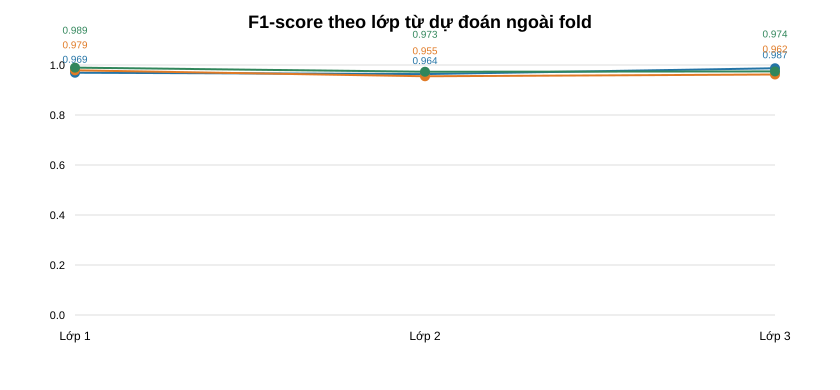

In [ ]:
from IPython.display import SVG, display
display(SVG('<svg xmlns="http://www.w3.org/2000/svg" width="840" height="390" viewBox="0 0 840 390"><rect width="100%" height="100%" fill="white"/><text x="420.0" y="28" text-anchor="middle" font-family="Arial" font-size="18" font-weight="bold">F1-score theo lớp từ dự đoán ngoài fold</text><line x1="75" y1="315.0" x2="775" y2="315.0" stroke="#ddd"/><text x="65" y="319.0" text-anchor="end" font-family="Arial" font-size="11">0.0</text><line x1="75" y1="265.0" x2="775" y2="265.0" stroke="#ddd"/><text x="65" y="269.0" text-anchor="end" font-family="Arial" font-size="11">0.2</text><line x1="75" y1="215.0" x2="775" y2="215.0" stroke="#ddd"/><text x="65" y="219.0" text-anchor="end" font-family="Arial" font-size="11">0.4</text><line x1="75" y1="165.0" x2="775" y2="165.0" stroke="#ddd"/><text x="65" y="169.0" text-anchor="end" font-family="Arial" font-size="11">0.6</text><line x1="75" y1="115.0" x2="775" y2="115.0" stroke="#ddd"/><text x="65" y="119.0" text-anchor="end" font-family="Arial" font-size="11">0.8</text><line x1="75" y1="65.0" x2="775" y2="65.0" stroke="#ddd"/><text x="65" y="69.0" text-anchor="end" font-family="Arial" font-size="11">1.0</text><circle cx="75.0" cy="72.73195876288659" r="5" fill="#2474A6"/><text x="75.0" y="62.73195876288659" text-anchor="middle" font-family="Arial" font-size="10" fill="#2474A6">0.969</text><circle cx="425.0" cy="74.0909090909091" r="5" fill="#2474A6"/><text x="425.0" y="64.0909090909091" text-anchor="middle" font-family="Arial" font-size="10" fill="#2474A6">0.964</text><circle cx="775.0" cy="68.24675324675326" r="5" fill="#2474A6"/><text x="775.0" y="58.24675324675326" text-anchor="middle" font-family="Arial" font-size="10" fill="#2474A6">0.987</text><polyline points="75.0,72.73195876288659 425.0,74.0909090909091 775.0,68.24675324675326" fill="none" stroke="#2474A6" stroke-width="2"/><circle cx="75.0" cy="70.31914893617022" r="5" fill="#E07A25"/><text x="75.0" y="48.31914893617022" text-anchor="middle" font-family="Arial" font-size="10" fill="#E07A25">0.979</text><circle cx="425.0" cy="76.26126126126127" r="5" fill="#E07A25"/><text x="425.0" y="54.26126126126127" text-anchor="middle" font-family="Arial" font-size="10" fill="#E07A25">0.955</text><circle cx="775.0" cy="74.49367088607593" r="5" fill="#E07A25"/><text x="775.0" y="52.49367088607593" text-anchor="middle" font-family="Arial" font-size="10" fill="#E07A25">0.962</text><polyline points="75.0,70.31914893617022 425.0,76.26126126126127 775.0,74.49367088607593" fill="none" stroke="#E07A25" stroke-width="2"/><circle cx="75.0" cy="67.63157894736844" r="5" fill="#31865B"/><text x="75.0" y="33.63157894736844" text-anchor="middle" font-family="Arial" font-size="10" fill="#31865B">0.989</text><circle cx="425.0" cy="71.75675675675674" r="5" fill="#31865B"/><text x="425.0" y="37.756756756756744" text-anchor="middle" font-family="Arial" font-size="10" fill="#31865B">0.973</text><circle cx="775.0" cy="71.41025641025641" r="5" fill="#31865B"/><text x="775.0" y="37.41025641025641" text-anchor="middle" font-family="Arial" font-size="10" fill="#31865B">0.974</text><polyline points="75.0,67.63157894736844 425.0,71.75675675675674 775.0,71.41025641025641" fill="none" stroke="#31865B" stroke-width="2"/><text x="75.0" y="340" text-anchor="middle" font-family="Arial" font-size="12">Lớp 1</text><text x="425.0" y="340" text-anchor="middle" font-family="Arial" font-size="12">Lớp 2</text><text x="775.0" y="340" text-anchor="middle" font-family="Arial" font-size="12">Lớp 3</text></svg>'))

## Bảng chi tiết theo lớp và ma trận nhầm lẫn ngoài fold

| Mô hình | Lớp | Precision | Recall | F1 | Hỗ trợ |
|---|---:|---:|---:|---:|---:|
| KNN | 1 | 0.940 | 1.000 | 0.969 | 47 |
| KNN | 2 | 1.000 | 0.930 | 0.964 | 57 |
| KNN | 3 | 0.974 | 1.000 | 0.987 | 38 |
| Gaussian Naive Bayes | 1 | 0.979 | 0.979 | 0.979 | 47 |
| Gaussian Naive Bayes | 2 | 0.981 | 0.930 | 0.955 | 57 |
| Gaussian Naive Bayes | 3 | 0.927 | 1.000 | 0.962 | 38 |
| Random Forest | 1 | 0.979 | 1.000 | 0.989 | 47 |
| Random Forest | 2 | 1.000 | 0.947 | 0.973 | 57 |
| Random Forest | 3 | 0.950 | 1.000 | 0.974 | 38 |

Ma trận dưới đây có hàng là lớp thật và cột là nhãn dự đoán. Đường chéo là dự đoán đúng.

| KNN | Dự đoán 1 | Dự đoán 2 | Dự đoán 3 |
|---|---:|---:|---:|
| Thật 1 | 47 | 0 | 0 |
| Thật 2 | 3 | 53 | 1 |
| Thật 3 | 0 | 0 | 38 |

| Gaussian Naive Bayes | Dự đoán 1 | Dự đoán 2 | Dự đoán 3 |
|---|---:|---:|---:|
| Thật 1 | 46 | 1 | 0 |
| Thật 2 | 1 | 53 | 3 |
| Thật 3 | 0 | 0 | 38 |

| Random Forest | Dự đoán 1 | Dự đoán 2 | Dự đoán 3 |
|---|---:|---:|---:|
| Thật 1 | 47 | 0 | 0 |
| Thật 2 | 1 | 54 | 2 |
| Thật 3 | 0 | 0 | 38 |

Các ma trận được tính từ dự đoán OOF đã lưu. Classification report gộp OOF và trung bình metric theo fold là hai cách tổng hợp khác nhau nên giá trị F1 của chúng có thể hơi khác. F-Score dùng trong bảng xếp hạng ở trên là trung bình F1-macro của mười outer folds, đúng quy ước đánh giá đã chọn.